# EXPT NO: 7 — TEXT PREPROCESSING AND EMBEDDING GENERATION USING NLP LIBRARIES

**NAME:** NIVASRI T  
**ROLL NO:** 24BAD081  
**DATE:** 12.10.2026


In [1]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

# Install / import libraries (Gensim may need installing in Colab)
!pip install -q gensim

import string
import numpy as np
import nltk
from nltk.corpus import brown, stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk import FreqDist
from gensim.models import Word2Vec

for pkg in ["brown", "stopwords", "punkt", "punkt_tab", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

print("Libraries imported and NLTK data downloaded.")

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 45.6 MB/s eta 0:00:00
Libraries imported and NLTK data downloaded.


## PART A: DATASET PREPARATION AND TEXT PREPROCESSING

### A1. Load the Brown Corpus and select a category (`news`)

In [2]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

print("Available categories:", brown.categories())

category = "news"
raw_sentences = [" ".join(sent) for sent in brown.sents(categories=category)]
print("\nSelected category :", category)
print("Number of sentences:", len(raw_sentences))

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Available categories: ['adventure', 'belles_lettres', 'editorial', 'fiction', 'government', 'hobbies', 'humor', 'learned', 'lore', 'mystery', 'news', 'religion', 'reviews', 'romance', 'science_fiction']

Selected category : news
Number of sentences: 4623


### A2. Examine sample sentences

In [3]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

for i in range(3):
    print(f"Sample {i+1}: {raw_sentences[i]}\n")

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Sample 1: The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .

Sample 2: The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .

Sample 3: The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. .



### A3. Lowercase, tokenize, remove punctuation & stop words, lemmatize

In [4]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()                                   # 1. lowercase
    tokens = word_tokenize(text)                          # 2. tokenization
    tokens = [t for t in tokens
              if t not in string.punctuation and t.isalpha()]   # 3. remove punctuation / symbols / numbers
    tokens = [t for t in tokens if t not in stop_words]   # 4. remove stop words
    tokens = [lemmatizer.lemmatize(t) for t in tokens]    # 5. lemmatization
    return tokens

processed = [preprocess(s) for s in raw_sentences]
processed = [s for s in processed if len(s) > 0]          # drop empty sentences
print("Sentences after preprocessing:", len(processed))

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Sentences after preprocessing: 4590


### A4. Display original and preprocessed text

In [5]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

for i in range(3):
    print(f"Original     : {raw_sentences[i]}")
    print(f"Preprocessed : {processed[i]}\n")

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Original     : The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
Preprocessed : ['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place']

Original     : The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
Preprocessed : ['jury', 'said', 'presentment', 'city', 'executive', 'committee', 'charge', 'election', 'deserves', 'praise', 'thanks', 'city', 'atlanta', 'manner', 'election', 'conducted']

Original     : The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to i

## PART B: VOCABULARY GENERATION AND WORD FREQUENCY ANALYSIS

In [6]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

all_words = [w for sent in processed for w in sent]
vocabulary = sorted(set(all_words))

print("Total tokens after preprocessing :", len(all_words))
print("Vocabulary size (unique words)   :", len(vocabulary))
print("First 20 vocabulary words        :", vocabulary[:20])

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Total tokens after preprocessing : 47682
Vocabulary size (unique words)   : 9896
First 20 vocabulary words        : ['aaron', 'abandoned', 'abandonment', 'abatuno', 'abbey', 'abe', 'abel', 'abell', 'abide', 'ability', 'ablaze', 'able', 'abner', 'aboard', 'abolish', 'abolition', 'abortive', 'abra', 'abraham', 'abroad']


In [7]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

fdist = FreqDist(all_words)

print("Ten most frequent words:\n")
print(f"{'Rank':<6}{'Word':<15}{'Frequency'}")
for rank, (word, freq) in enumerate(fdist.most_common(10), start=1):
    print(f"{rank:<6}{word:<15}{freq}")

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Ten most frequent words:

Rank  Word           Frequency
1     said           406
2     year           260
3     would          249
4     new            241
5     state          223
6     one            222
7     last           177
8     two            174
9     first          158
10    president      155


NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------


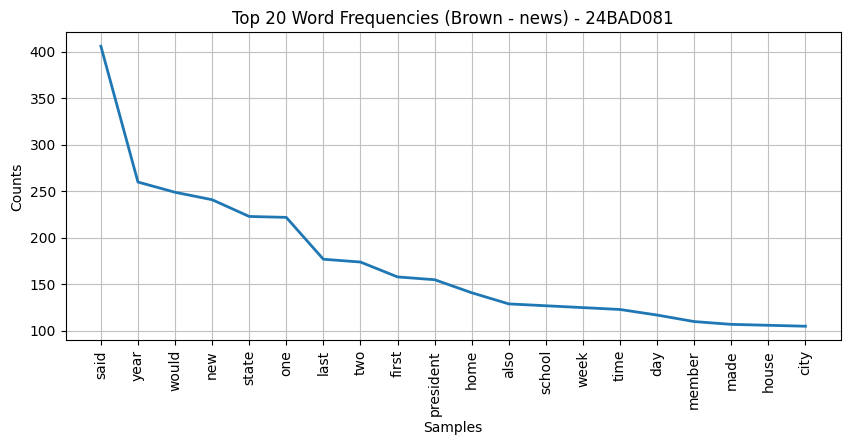

In [8]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
fdist.plot(20, title="Top 20 Word Frequencies (Brown - news) - 24BAD081")
plt.show()

In [9]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

# Tokenized sentences are prepared for Word2Vec (list of lists of tokens)
sentences_for_w2v = processed
print("Number of training sentences:", len(sentences_for_w2v))
print("Example:", sentences_for_w2v[0])

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Number of training sentences: 4590
Example: ['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place']


## PART C: WORD EMBEDDING GENERATION USING WORD2VEC

### C1. Train Word2Vec (Skip-gram, 100 dimensions, window = 5)

In [10]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

w2v_model = Word2Vec(
    sentences=sentences_for_w2v,
    vector_size=100,   # embedding dimension
    window=5,          # context window size
    min_count=2,       # ignore words appearing fewer than 2 times
    sg=1,              # 1 = Skip-gram, 0 = CBOW
    workers=1,
    epochs=20,
    seed=42
)

print("Word2Vec model trained successfully.")
print("Vocabulary size in Word2Vec model:", len(w2v_model.wv))

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Word2Vec model trained successfully.
Vocabulary size in Word2Vec model: 5164


### C2. Embedding vector of a selected word and its dimensions

In [11]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

word = "president"
vector = w2v_model.wv[word]

print(f"Word      : {word}")
print(f"Dimensions: {vector.shape}  (vector length = {len(vector)})")
print(f"\nEmbedding vector:\n{vector}")

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Word      : president
Dimensions: (100,)  (vector length = 100)

Embedding vector:
[-0.46862677 -0.34687892  0.03179901  0.55034655  0.09511758  0.10706135
  0.19001865 -0.11513062  0.04622346 -0.81460273  0.06641307 -0.12433771
  0.418521    0.6134883  -0.54983807 -0.0619005   0.20634198  0.47060484
 -0.5918648   0.55114776  0.22190705  0.70620847  0.31865    -0.0307857
 -0.06375659  0.48365194  0.13300171  0.6537125  -0.30234736 -0.24625866
  0.12025029  0.29717663 -0.12499672  0.07632045  0.5736875   0.78230625
  0.06206762 -0.29745036 -0.01643673  0.23318715  0.3602136  -0.02973006
  0.2402505  -0.13556376 -0.04162902  0.03041825  0.8489987  -0.34291106
  0.5194542  -0.8888618  -0.32938674 -0.2273067   0.21481404 -0.24398638
  0.00191743  0.47794917 -0.23487262  0.25037372  0.05995601  0.16742569
 -0.01928869 -0.3339849   0.36119872 -0.11035186  0.25993705  0.11279844
  0.2308689  -0.4466032  -0.1949747

### C3. Five most similar words

In [12]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

for target in ["school", "president", "year"]:
    print(f"\nTop 5 words most similar to '{target}':")
    for w, score in w2v_model.wv.most_similar(target, topn=5):
        print(f"   {w:<15} {score:.4f}")

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------

Top 5 words most similar to 'school':
   junior          0.8168
   teacher         0.8072
   senior          0.7851
   principal       0.7827
   deaf            0.7627

Top 5 words most similar to 'president':
   inauguration    0.7516
   vice            0.7347
   jacqueline      0.7194
   stevenson       0.7012
   kennedy         0.6972

Top 5 words most similar to 'year':
   september       0.7442
   january         0.7313
   august          0.7144
   month           0.7046
   equal           0.6961


## PART D: WORD SIMILARITY ANALYSIS AND EXPERIMENT MANAGEMENT

In [13]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

word_pairs = [("court", "judge"), ("year", "month"), ("president", "government")]

results = []
for w1, w2 in word_pairs:
    sim = w2v_model.wv.similarity(w1, w2)    # cosine similarity
    results.append((w1, w2, sim))
    print(f"Cosine similarity ({w1}, {w2}) = {sim:.4f}")

best = max(results, key=lambda x: x[2])
print(f"\nMost similar pair: ({best[0]}, {best[1]}) with similarity = {best[2]:.4f}")

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
Cosine similarity (court, judge) = 0.8110
Cosine similarity (year, month) = 0.7046
Cosine similarity (president, government) = 0.2762

Most similar pair: (court, judge) with similarity = 0.8110


In [14]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

# Manual cosine-similarity check using NumPy (verifies the Gensim result)
def cosine(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

for w1, w2 in word_pairs:
    print(f"{w1:<10} {w2:<12} manual cosine = {cosine(w2v_model.wv[w1], w2v_model.wv[w2]):.4f}")

NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------
court      judge        manual cosine = 0.8110
year       month        manual cosine = 0.7046
president  government   manual cosine = 0.2762


NAME    : NIVASRI T
ROLL NO : 24BAD081
----------------------------------------


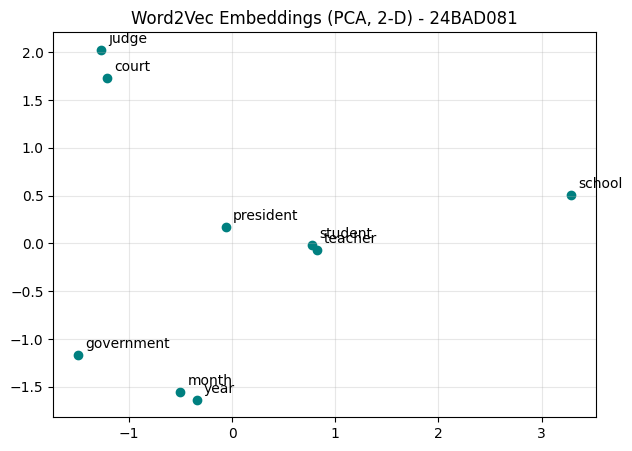

In [15]:
print("NAME    : NIVASRI T")
print("ROLL NO : 24BAD081")
print("-" * 40)

# Optional: visualise embeddings in 2-D with PCA
from sklearn.decomposition import PCA

words = ["court", "judge", "year", "month", "president", "government", "school", "teacher", "student"]
words = [w for w in words if w in w2v_model.wv]
coords = PCA(n_components=2).fit_transform([w2v_model.wv[w] for w in words])

plt.figure(figsize=(7, 5))
plt.scatter(coords[:, 0], coords[:, 1], color="teal")
for w, (x, y) in zip(words, coords):
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(5, 5))
plt.title("Word2Vec Embeddings (PCA, 2-D) - 24BAD081")
plt.grid(alpha=0.3)
plt.show()